# Proof figure, 2026-10-29

The proof-of-concept figure for the paper.
- **Panel a** is one t-SNE of nine generator classes. One silo per family surrounds it, showing the recordings behind the ringed points.
- **Panel b** shows four fixed class contrasts.

Data are the 2026-10-14 p90 feature bank (283 SPIs, computation r9) with ordered z (`unified_ordered_v3`); [proof_p90_261021](proof_p90_261021.ipynb) holds the full ten-class analysis.

Every setting is frozen in `research/proof/p90/configs/analysis/proof-figure-261029.yaml`: classes, colours, t-SNE, KDE islands, contrasts and panel-a layout. The code is `research/proof/p90/proof_figure.py`.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.proof.p90.refresh_proof_figures import load_bank
from research.proof.p90.proof_figure import (load_config, fit_embedding, select_contrasts, select_examples,
                                             choose_layout, plot_proof_figure,
                                             export_carpets, export_glyphs)
FIGURE = load_config()
OUT = ROOT / 'results/proof/figure-261029'
bank = load_bank(ROOT / 'data/proof/refresh-261014/features.npz', expected_spis=283, contract='unified_ordered_v3')

## Embedding and checks

Preprocessing and PCA50 are fitted on the nine displayed classes only, as in the 261014 protocol. t-SNE then uses openTSNE with Student-t degrees of freedom 5. The lighter kernel tails spread points within islands so that M and T stay legible ([Kobak et al. 2020](https://arxiv.org/abs/1902.05804)).

Check that the classes are already separated before t-SNE: a 5-nearest-neighbour classifier on PCA50, holding out each M/T cell in turn. Preprocessing and PCA see every cell, so this is not a fully held-out test.

In [2]:
embedding = fit_embedding(bank, OUT, FIGURE)
print(f"{embedding['audit']['datasets']} recordings, {embedding['audit']['features']:,} coordinates; "
      f"PCA50 5NN accuracy, each M/T cell held out: {embedding['audit']['pca50_knn5_cell_held_out_accuracy']:.3f}")
contrasts = select_contrasts(bank, OUT, FIGURE)
contrasts[['class_a', 'class_b', 'spi_a', 'spi_b', 'training_auc_oriented', 'display_auc_fixed_orientation']].round(3)

810 recordings, 23,176 coordinates; PCA50 5NN accuracy, each M/T cell held out: 0.998


,class_a,class_b,spi_a,spi_b,training_auc_oriented,display_auc_fixed_orientation
0,gaussian-noise,cauchy-noise,cov_EmpiricalCovariance,spearmanr,1.0,1.0
1,var-self-0.7_total-0.2,var-self-0.2_total-0.7,tlmi_kraskov_NN-4,te_kraskov_NN-4_k-1_kt-1_l-1_lt-1,1.0,1.0
2,kuramoto_omega-fast,kuramoto_omega-slow,corr_pearson_tau-1,xcorr_max_sig-True,1.0,1.0
3,sti-i,fdstc,corr_pearson_tau-1,corr_pearson_tau-2,1.0,1.0


## Example recordings

For each class, the figure shows three recordings, one each at (M, T) = (8, 500), (16, 1000) and (32, 2000). Each is the display instance (6–9) nearest the medoid of its cell in t-SNE.
- Recordings are regenerated from the frozen generation config, so each carpet is the exact recording behind a ringed point.
- Carpets share one scale: height ∝ M, and width ∝ the first T/5 samples.
- Each carpet is scaled robustly per channel, using the icefire map limited to the 99th percentile of |x|, as in the other figures.

In [3]:
examples = select_examples(bank, embedding, FIGURE, OUT)
import pandas as pd
pd.DataFrame([{k: v for k, v in e.items() if k != 'carpet'} for e in examples]).pivot_table(
    index='name', columns='M', values='instance', aggfunc='first')

M,8,16,32
name,,,
cauchy-noise,6,7,6
fdstc,6,8,6
gaussian-noise,8,7,8
kuramoto_omega-fast,7,8,8
kuramoto_omega-slow,9,6,9
sti-i,7,8,8
var-self-0.2_total-0.7,8,6,8
var-self-0.7_total-0.2,9,6,9
wave-1d,6,8,8


## Layout

t-SNE axes carry no meaning, so the map is rotated or reflected once. A search over silo sides and orders, the variant order within each silo, and orientation gives short leaders that neither cross each other nor run over other islands, with a free corner for the inset key. The result is frozen in the YAML (`panel_a`). Set `SEARCH = True` to rerun it (about 20 s).

In [4]:
SEARCH = False
if SEARCH:
    print(choose_layout(embedding['tsne'], bank['y'][embedding['indices']], FIGURE))
else:
    print({k: FIGURE['panel_a'][k] for k in ['columns', 'variant_order', 'rotation_deg', 'reflect_x']})

{'columns': {'left': ['CML', 'Kuramoto'], 'right': ['VAR', 'Wave equation', 'Noise']}, 'variant_order': {'CML': ['fdstc', 'sti-i'], 'VAR': ['var-self-0.2_total-0.7', 'var-self-0.7_total-0.2']}, 'rotation_deg': 60, 'reflect_x': True}


## Figure

Two versions: with the bottom class legend and without it. Once the silos name every variant in its colour and the raincloud ticks repeat the names, the legend may be redundant.

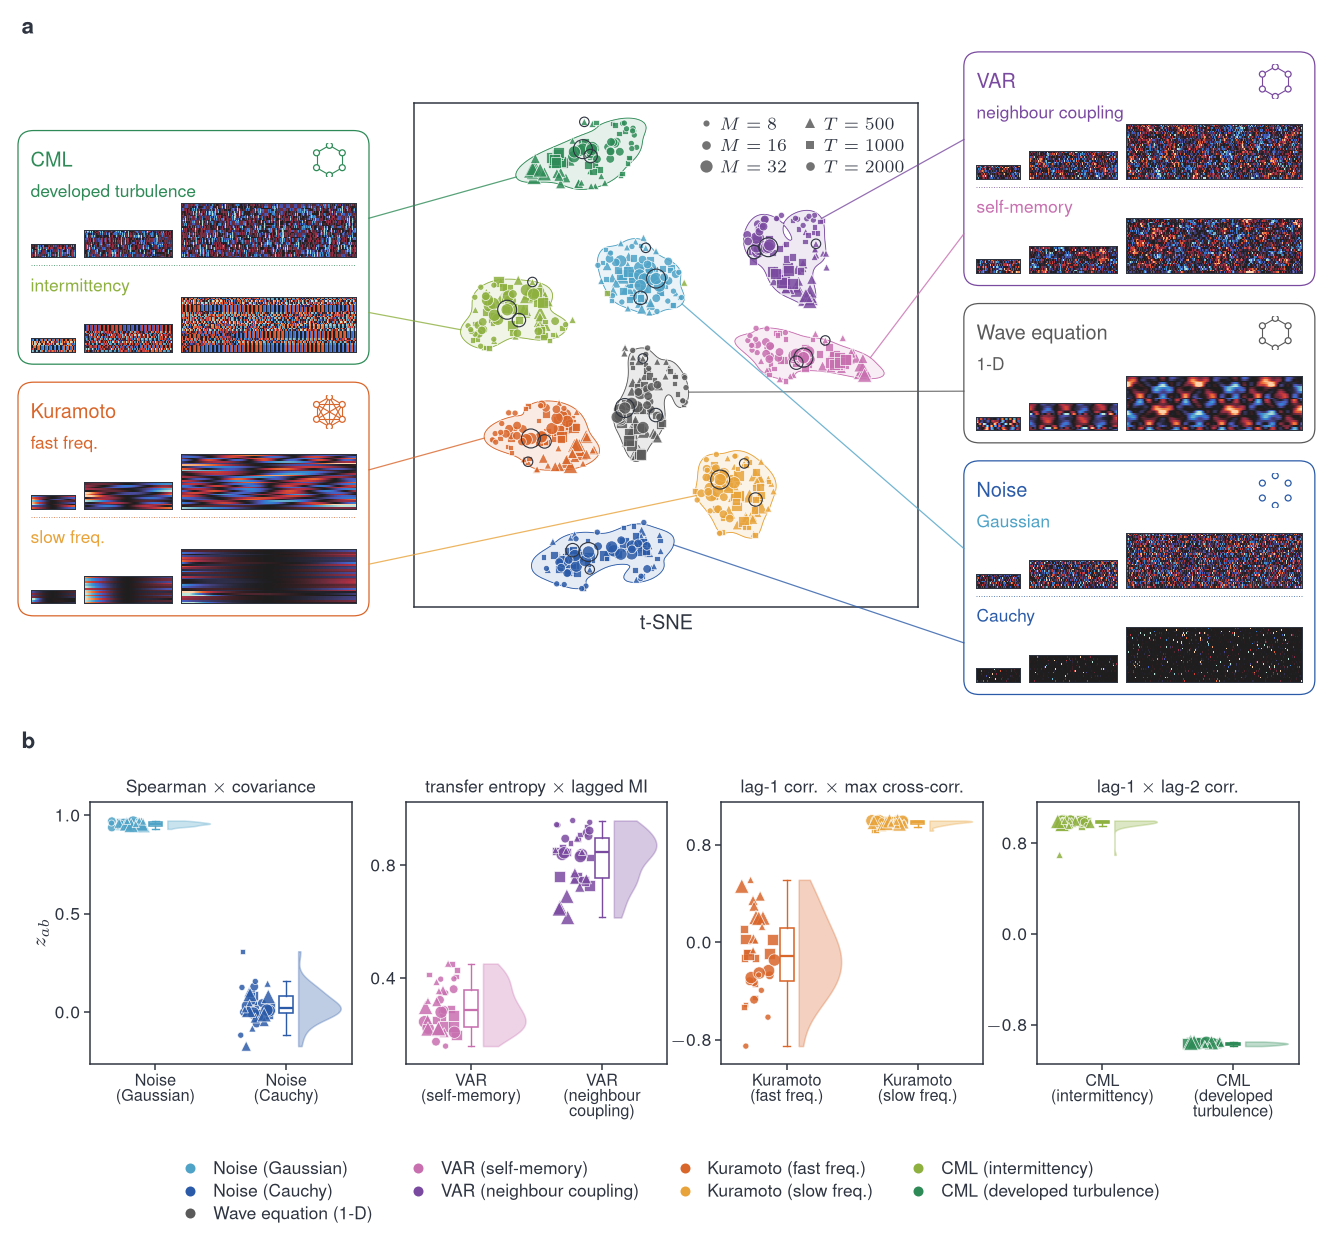

In [5]:
fig = plot_proof_figure(bank, embedding, contrasts, examples, FIGURE, OUT, legend=True, name='proof-figure-legend')
plt.show()

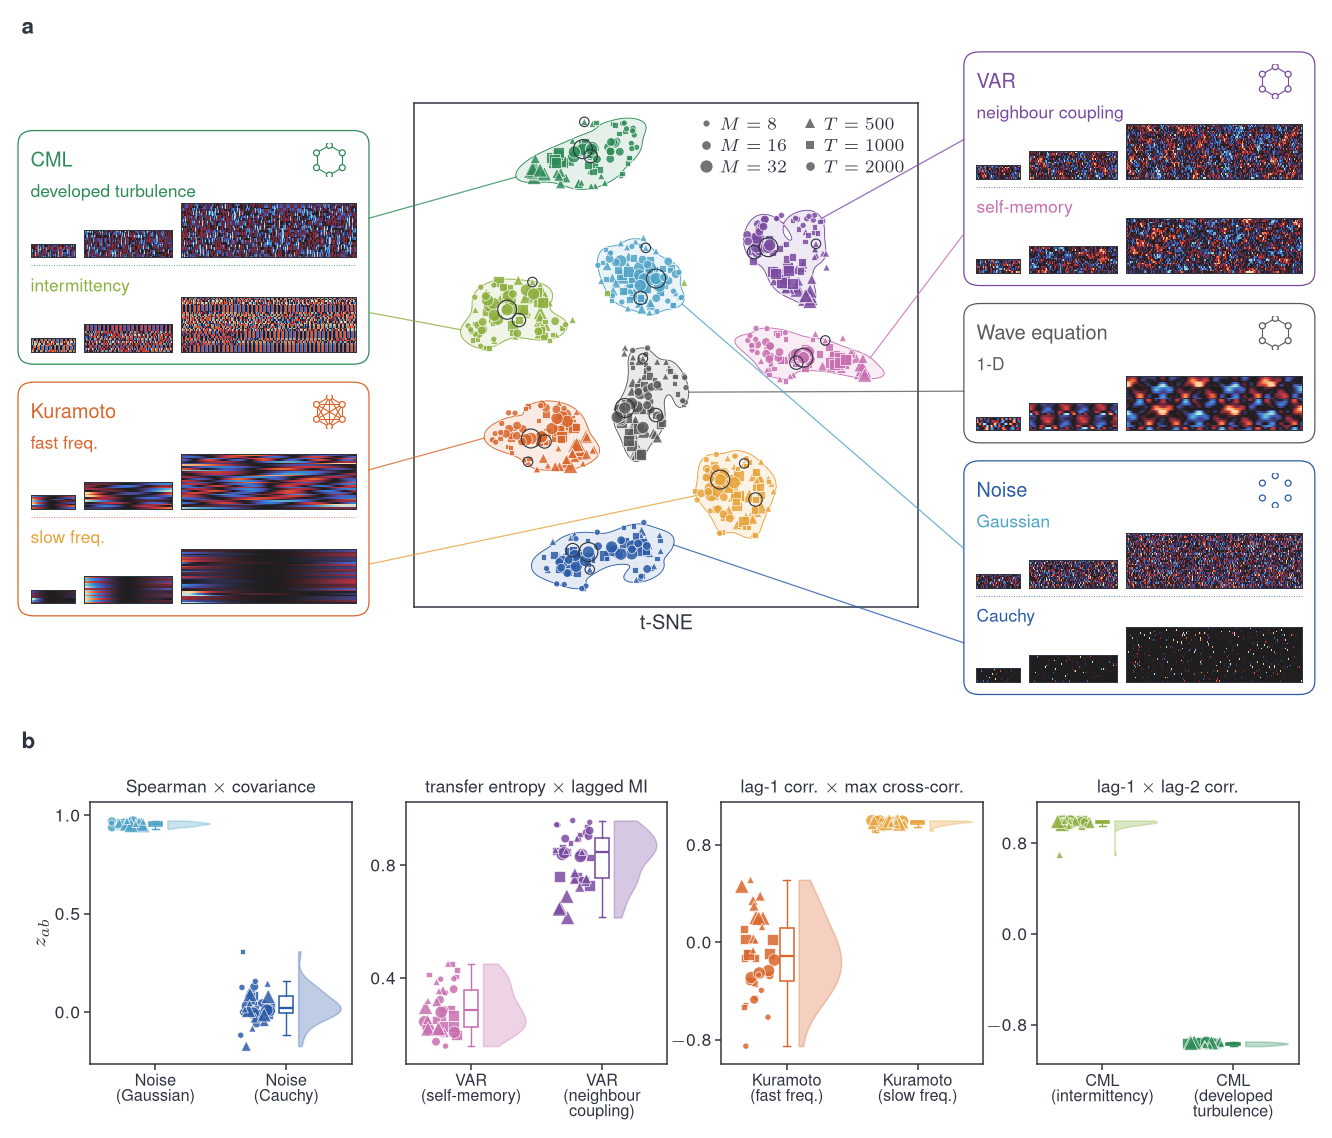

In [6]:
fig = plot_proof_figure(bank, embedding, contrasts, examples, FIGURE, OUT, legend=False, name='proof-figure')
plt.show()

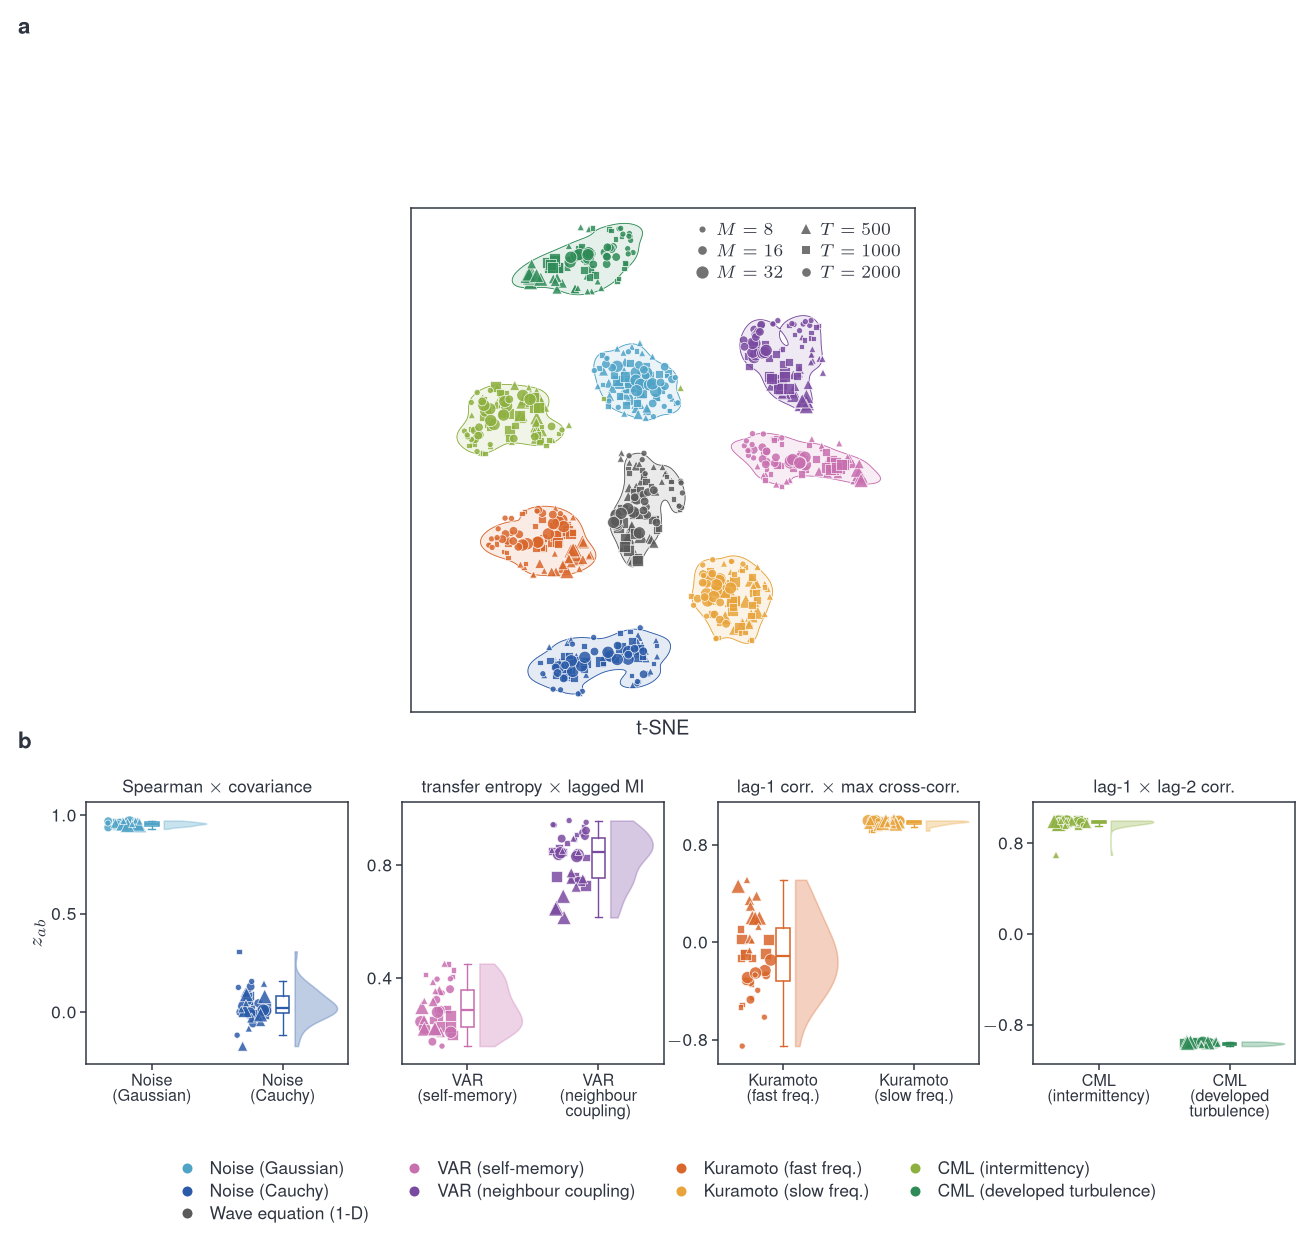

In [7]:
# Without silos or rings, for arranging carpets by hand in draw.io: the embedding sits just above panel b.
fig = plot_proof_figure(bank, embedding, contrasts, examples, FIGURE, OUT, legend=True, silos=False, rings=False,
                        name='proof-figure-nosilos')
plt.show()


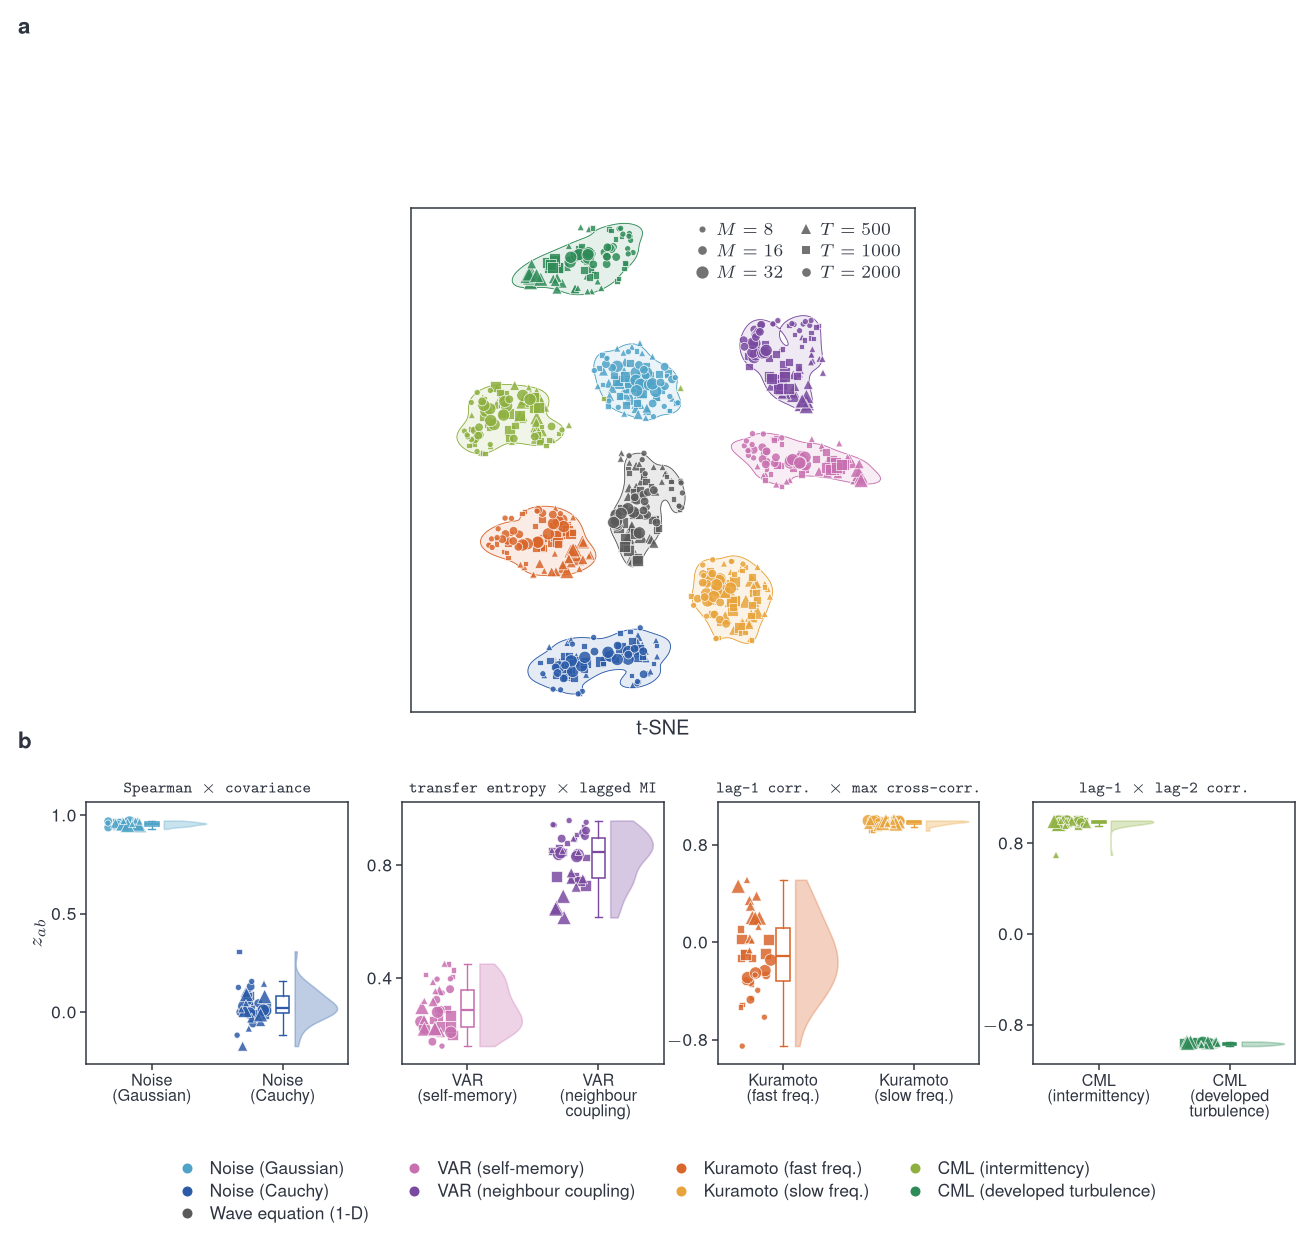

In [8]:
# Variant: raincloud titles in typewriter type.
fig = plot_proof_figure(bank, embedding, contrasts, examples, FIGURE, OUT, legend=True, silos=False, rings=False,
                        title_tt=True, name='proof-figure-nosilos-tt')
plt.show()


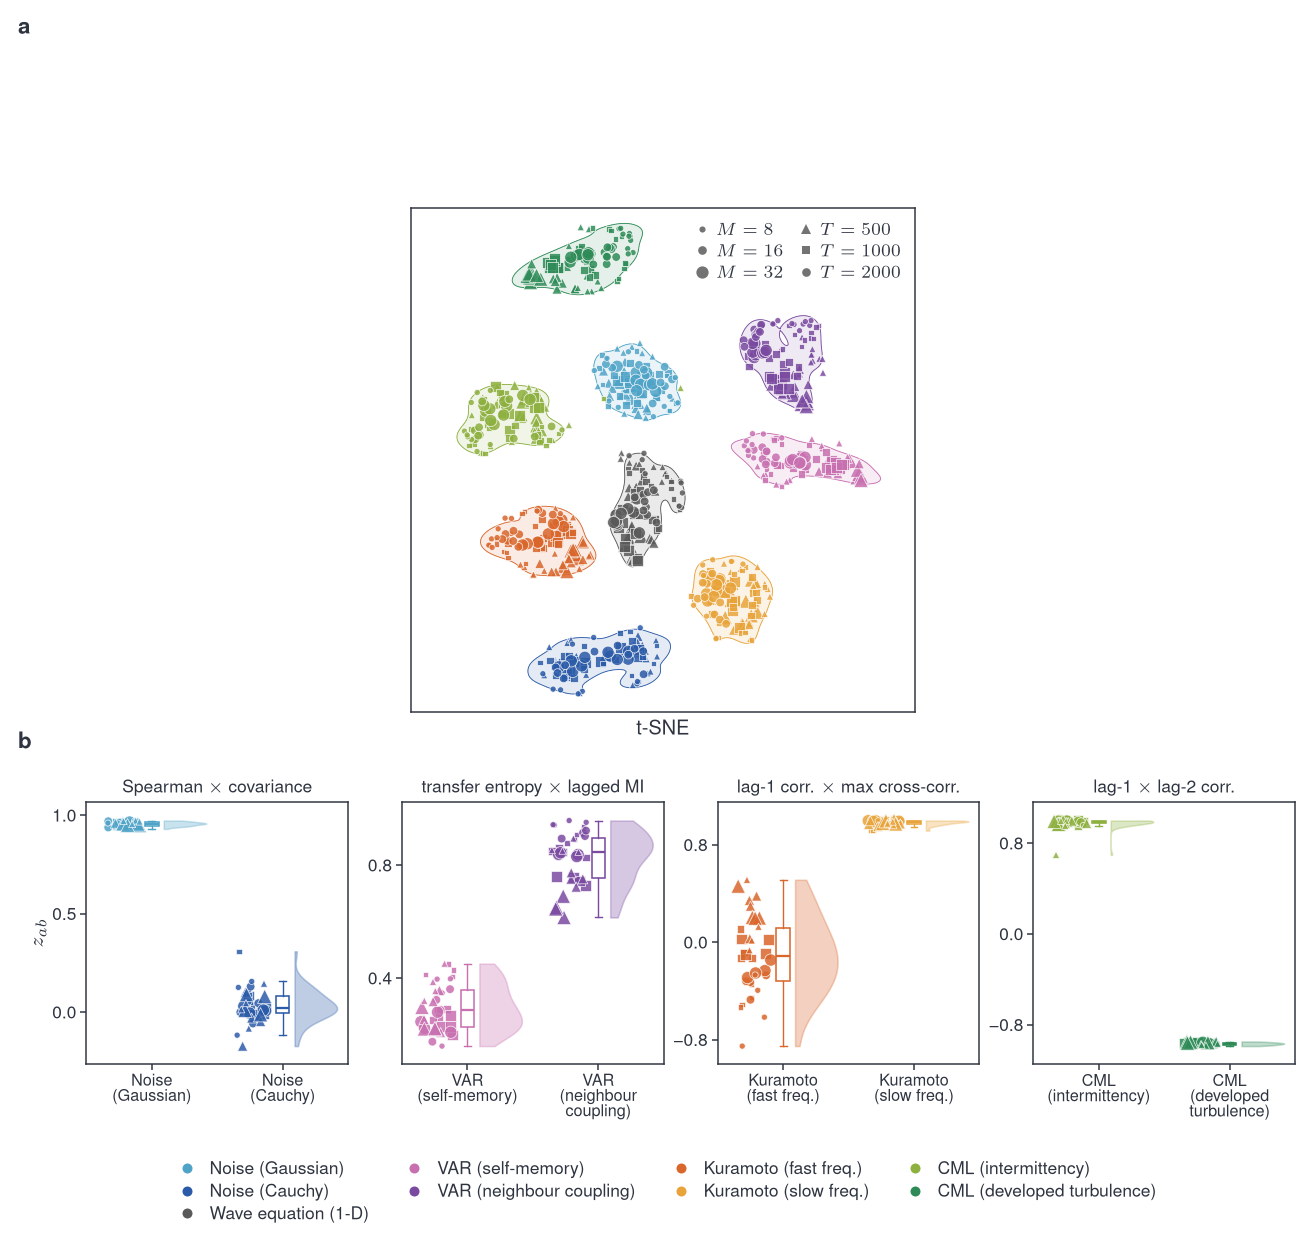

In [9]:
# Variant: text in Helvetica (TeX helvet; Nature asks for sans-serif), math kept in Computer Modern.
fig = plot_proof_figure(bank, embedding, contrasts, examples, FIGURE, OUT, legend=True, silos=False, rings=False,
                        sans=True, name='proof-figure-nosilos-sans')
plt.show()


## Exports for draw.io

Every class at every M/T cell and every instance (0–9), one SVG per recording at final size, a folder per class with a contact sheet; settings in `panel_a.carpets`.
- Square-root scaling: height $0.15\sqrt{M/8}$ in, width $0.315\sqrt{T/500}$ in, so M=32 is twice as tall as M=8 and T=2000 twice as wide as T=500.
- Width is a clip on one time ruler, 238 samples per inch: 75, 106 and 150 samples for T = 500, 1000 and 2000.
- Intermittency shows every 12th sample, which strobes the period-3 laminar orbit; the SPIs were computed on every sample. At T=500 only 42 strided samples exist, so its columns are wider.
- Kuramoto also gets `_whole` views: the whole record decimated to the same width. The clip is under half a fast-oscillator period, so fast and slow look alike in it.
- `carpets/index.csv` lists each file with its `embedding_row`, for marking chosen recordings in panel a.
- Glyphs: `topology/` holds the family glyphs; `weighted/` holds per-class glyphs with line width ∝ coupling weight (self-loops: weight on a node's own past; dotted: near-zero coupling; dashed hub: repulsive mean-field coupling).

In [10]:
cells = [(m, t) for m in (8, 16, 32) for t in (500, 1000, 2000)]
index = export_carpets(select_examples(bank, embedding, FIGURE, sizes=cells, all_instances=True), FIGURE, OUT/'carpets')
export_glyphs(FIGURE, OUT/'glyphs')
print(f'{len(index)} carpets in {index.name.nunique()} class folders, each with contact-sheet.png')


990 carpets in 9 class folders, each with contact-sheet.png


## Caption notes

- **Colour** gives the class; a family's variants take neighbouring hues. Marker area ∝ M; shape gives T.
- **Islands** are tinted 95% highest-density regions of a Gaussian KDE, with a thin contour. Island areas, gaps, positions and contour shapes carry no meaning, and the map is rotated.
- **Ringed points** are the recordings shown in the silos. Carpet height ∝ M; width ∝ the first T/5 samples.
- **Silo glyphs** show the generator's coupling topology: none for noise, a ring for VAR and CML, all-to-all for Kuramoto, a ring for the wave equation (periodic lattice). Generator equations and parameters belong in the SI table.
- **Panel b.** Each contrast coordinate was chosen for mechanistic readability among coordinates with training AUC ≥ .995 in every M/T cell (instances 0–5). The rainclouds show instances 6–9. These are illustrations, not unique or confirmatory axes. Readings are in the YAML (`contrasts[].reading`).